In [2]:
import torch
import torch.nn as nn

In [9]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 35.2 MB/s  0:00:00 41.7 MB/s eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 40.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.8/6.8 MB 44.3 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/7 [numpy]
      Successfully uninstalled numpy-1.26.4m╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/7 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]ourpy]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /usr/local/Cellar/jupyterlab/4.2.5_1/libexec/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### 
- nn.Linear() -> `y = xA^T + b` (single linear transformation)
- Linear function -> `y = 2x + 5`
- Non-linear function -> `y = x^2 + 2x + 5`
- activation functions  are non-linear functions
- activation function determines how a neuron transforms its input before passing the result to the next layer
- without activation functions, a neural network consisting of multiple linear layers would behave like a single linear transformation
- even though we have 3 layers, the overall model is still mathematically linear
- adding activation functions allows the network to learn `nonlinear relationships` which helps to solving complex problems such as image recognition, fraud detection, NLP, and speech recognition

In [3]:
model = nn.Sequential(
    nn.Linear(in_features=2, out_features=8, bias = True), # Layer 1, 2 -> input_features
    nn.ReLU(),       # activation functions  are non linear functions
    nn.Linear(8, 4), # Layer 2
    nn.ReLU(),       # activation functions
    nn.Linear(4, 1)  # Layer 3, 1 -> output_features
)

print(model)

Sequential(
  (0): Linear(in_features=2, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=4, bias=True)
  (3): ReLU()
  (4): Linear(in_features=4, out_features=1, bias=True)
)


### Sigmoid Activation Function
- it converts any real-valued input into a number between 0 and 1
$$
f(x)=\frac{1}{1+e^{-x}}
$$
- mostly used for `binary classification` when you want to predict a probability eg. fraud detection, cancer/no cancer
- $$ \left\lbrace-10\le x\le10\right\rbrace $$

In [5]:
x = torch.tensor([-5.0, -2.0, 0.0, 2.0, 5.0])

sigmoid = nn.Sigmoid()

output = sigmoid(x)

print(output)

tensor([0.0067, 0.1192, 0.5000, 0.8808, 0.9933])


In [7]:
# a probability of 0.92 means the model estimates a 92% probability of fraud

prob = torch.tensor([0.92])
if prob >= 0.5:
    print("fradulent transaction")
else:
    print("Legitimate transaction")

fradulent transaction


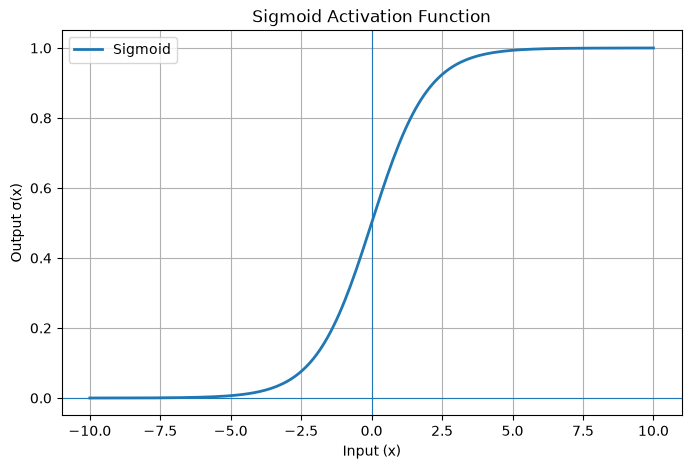

In [10]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Generate input values
x = torch.linspace(-10, 10, 200)

# Apply sigmoid
sigmoid = nn.Sigmoid()
y = sigmoid(x)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(x.numpy(), y.numpy(), label="Sigmoid", linewidth=2)

plt.title("Sigmoid Activation Function")
plt.xlabel("Input (x)")
plt.ylabel("Output σ(x)")
plt.axhline(y=0, linewidth=0.8)
plt.axvline(x=0, linewidth=0.8)
plt.grid(True)
plt.legend()

plt.show()

### ReLU (Rectified Linear Unit)
- ReLU is one of the most widely used activation functions in deep learning
- It replaces all negative values with zero while keeping positive values unchanged
$$
f(x)=\max(0,x)
$$

In [12]:
x = torch.tensor([-5.0, -2.0, 0.0, 2.0, 5.0])

relu = nn.ReLU()

output = relu(x)

print(output)

tensor([0., 0., 0., 2., 5.])


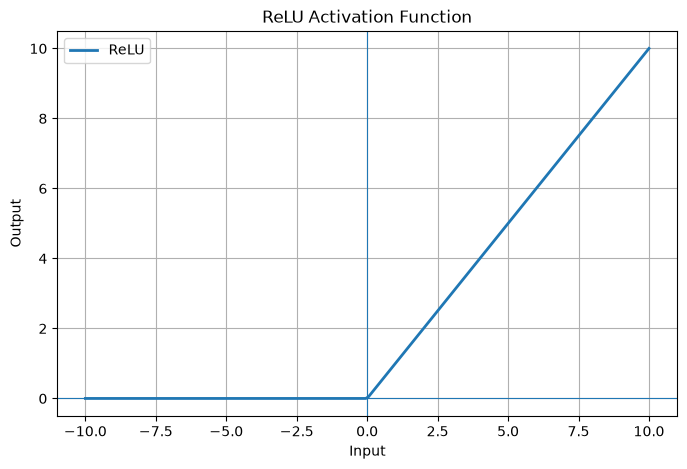

In [13]:
# Generate input values
x = torch.linspace(-10, 10, 200)

# Apply ReLU
relu = nn.ReLU()
y = relu(x)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(x.numpy(), y.numpy(), label="ReLU", linewidth=2)

plt.title("ReLU Activation Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.axhline(y=0, linewidth=0.8)
plt.axvline(x=0, linewidth=0.8)
plt.grid(True)
plt.legend()

plt.show()

In [30]:
model = nn.Sequential(
    nn.Linear(10, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)
print(model)


model = nn.Sequential(
    nn.Linear(10, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.Tanh(),
    nn.Linear(32, 1)
)
print(model)

Sequential(
  (0): Linear(in_features=10, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Sequential(
  (0): Linear(in_features=10, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): Tanh()
  (4): Linear(in_features=32, out_features=1, bias=True)
)


### Tanh (Hyperbolic Tangent)
- Tanh transforms values into a range between -1 and 1
- It can be useful in `recurrent neural networks`
- It represents both positive and negative activations
$$
f(x)=\frac{e^x-e^{-x}}{e^x+e^{-x}}
$$

In [15]:
import torch
import torch.nn as nn

x = torch.tensor([-5.0, -2.0, 0.0, 2.0, 5.0])

tanh = nn.Tanh()

output = tanh(x)

print(output)

tensor([-0.9999, -0.9640,  0.0000,  0.9640,  0.9999])


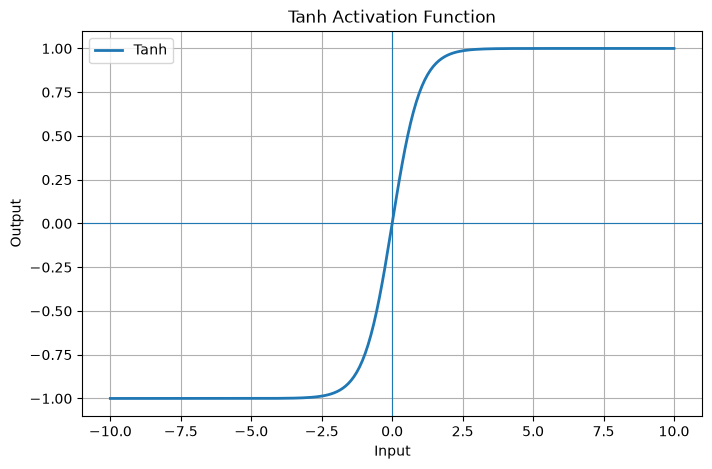

In [29]:
# Generate input values
x = torch.linspace(-10, 10, 200)

# Apply ReLU
tanh = nn.Tanh()
y = tanh(x)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(x.numpy(), y.numpy(), label="Tanh", linewidth=2)

plt.title("Tanh Activation Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.axhline(y=0, linewidth=0.8)
plt.axvline(x=0, linewidth=0.8)
plt.grid(True)
plt.legend()

plt.show()

### Softmax
- Used for `multiclass classification` (Cat, Dog, Bird, ...)
- It suppose a neural network predicts 3 classes (Cat, Dog, Bird)
- The raw outputs (logits) are: `X = [cat=2.0, dog=1.0, bird=0.1]`
- It will convert these 3 values into probability
$$
f(x_i)=\frac{e^{x_i}}{\sum_{j=1}^{n}e^{x_j}}
$$

- e^(2.0) = 7.3891,
- e^(1.0) = 2.7183,
- e^(0.1) = 1.1052

denominator = 7.3891 + 2.7183 + 1.1052 = 11.2126

- P(cat) = 7.3891 / 11.2126 = 0.6589
- P(dog) = 2.7183 / 11.2126 = 0.2424
- P(bird) = 1.1052 / 11.2126 = 0.0986

Sum of all probs must equal one: 0.6589 + 0.2424 + 0.0986 = 1.0

- The model predicts `Cat` ~ 65.89%, because it has the highest probability

In [31]:
import torch
import torch.nn as nn

# Raw model predictions (logits)
logits = torch.tensor([2.0, 1.0, 0.1])

# Apply softmax
softmax = nn.Softmax(dim=0)

probabilities = softmax(logits)

print(probabilities)
print(probabilities.sum())

tensor([0.6590, 0.2424, 0.0986])
tensor(1.0000)


### Differences between Sigmoid and Softmax
- Sigmoid output (0 to 1) vs. Softmax output (0 to 1)
- Sigmoid output doesn't sum to 1.0, but Softmax output sums to 1.0
- Sigmoid used for Binary classification  (Spam vs. Not Spam), but Softmax for Multiclass classification (cat, dog, bird)

### HomeWork

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Generate input values
x = torch.linspace(-5, 5, 200)

# Activation functions
activations = {
    "Sigmoid": nn.Sigmoid(),
    "ReLU": nn.ReLU(),
    "Leaky ReLU": nn.LeakyReLU(0.01),
    "Tanh": nn.Tanh(),
    "GELU": nn.GELU(),
    "SiLU": nn.SiLU()
}

# Create 2x3 plots
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, (name, activation) in zip(axes.flatten(), activations.items()):

    y = activation(x)

    ax.plot(x.numpy(), y.numpy(), label=name)

    # Add axes reference lines
    ax.axhline(y=0, linewidth=0.8)
    ax.axvline(x=0, linewidth=0.8)

    ax.set_title(name)
    ax.set_xlabel("Input (x)")
    ax.set_ylabel("Output f(x)")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()